# 03. Случайный эффект площадки


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Та же H-модель, плюс случайный эффект завода: часть разброса `trait` — площадка, а не линия изделия.

| | |
|---|---|
| **Данные** | `data/lineage.csv`, `data/measurements.csv`, `data/markers.csv` |
| **Цель** | Две Z-матрицы и блочная K: изделие + завод |
| **Результат** | Оценки изделий и эффекты площадок |


In [2]:
library(rrBLUP)
library(AGHmatrix)
library(Matrix)
library(pedigreeTools)
library(dplyr)
library(ggplot2)
library(tidyr)
library(stringr)
library(e1071)
library(knitr)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Attaching package: ‘tidyr’



The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack



In [3]:
z_score_filter <- function(pipeline, threshold) {
  z <- abs((pipeline$trait - mean(pipeline$trait, na.rm = TRUE)) / sd(pipeline$trait, na.rm = TRUE))
  pipeline %>% filter(!(z > threshold))
}

bending <- function(matrix, epsilon) {
  e <- eigen(matrix)
  e$values[e$values < epsilon] <- epsilon
  out <- e$vectors %*% diag(e$values) %*% t(e$vectors)
  rownames(out) <- rownames(matrix)
  colnames(out) <- colnames(matrix)
  out
}

scale_g_to_a <- function(A_matrix, G_matrix) {
  common <- intersect(rownames(G_matrix), rownames(A_matrix))
  G_matrix <- G_matrix[common, common, drop = FALSE]
  A22 <- A_matrix[common, common, drop = FALSE]
  G_matrix * (sum(diag(A22)) / sum(diag(G_matrix)))
}

prepare_ids <- function(lineage, measurements, markers = NULL) {
  ids <- unique(c(measurements$item_id, lineage$item_id, lineage$parent_a, lineage$parent_b))
  if (!is.null(markers)) ids <- unique(c(ids, markers$item_id))
  ids <- ids[ids != 0]
  levels <- as.character(sort(unique(ids)))
  recode <- function(x) as.integer(factor(as.character(x), levels = levels))
  lineage <- lineage %>%
    mutate(
      item_id = recode(item_id),
      parent_a = ifelse(parent_a == 0, 0L, recode(parent_a)),
      parent_b = ifelse(parent_b == 0, 0L, recode(parent_b))
    )
  measurements <- measurements %>% mutate(item_id = recode(item_id))
  if (!is.null(markers)) {
    markers <- markers %>% mutate(item_id = recode(item_id))
  }
  list(lineage = lineage, measurements = measurements, markers = markers, levels = levels)
}

order_lineage <- function(lineage, keep_ids) {
  ped <- editPed(label = lineage$item_id, sire = lineage$parent_a, dam = lineage$parent_b)
  ped <- ped[, c("label", "sire", "dam")]
  names(ped) <- c("item_id", "parent_a", "parent_b")
  ped <- ped %>% filter(item_id %in% keep_ids)
  ped$parent_a[!(ped$parent_a %in% ped$item_id)] <- 0
  ped$parent_b[!(ped$parent_b %in% ped$item_id)] <- 0
  rownames(ped) <- ped$item_id
  ped
}


In [4]:
measurements <- read.csv("data/measurements.csv") %>%
  dplyr::select(item_id, batch_mass, batch_no, line_age, event_season, event_year, factory, trait)
markers <- read.csv("data/markers.csv", colClasses = c(item_id = "character", panel = "character"))
lineage <- read.csv("data/lineage.csv")
measurements <- drop_na(measurements)
lineage <- lineage %>%
  filter(item_id %in% measurements$item_id | parent_a %in% measurements$item_id | parent_b %in% measurements$item_id)
measurements <- measurements %>% filter(item_id %in% lineage$item_id)
markers <- markers %>% filter(item_id %in% as.character(measurements$item_id))
prep <- prepare_ids(lineage, measurements, markers)
lineage_bl <- order_lineage(prep$lineage, prep$measurements$item_id)
meas_bl <- prep$measurements %>%
  mutate(
    event_season = factor(event_season),
    event_year = factor(event_year),
    factory = factor(factory)
  )
mark_bl <- prep$markers


# 1. H и блочная K


In [5]:
A <- Amatrix(lineage_bl[, c("item_id", "parent_a", "parent_b")], ploidy = 2)
if (nrow(A) == nrow(lineage_bl)) {
  rownames(A) <- as.character(lineage_bl$item_id)
  colnames(A) <- as.character(lineage_bl$item_id)
} else {
  rownames(A) <- as.character(rownames(A))
  colnames(A) <- as.character(colnames(A))
}
meas_bl <- meas_bl[as.character(meas_bl$item_id) %in% rownames(A), ]
meas_bl <- meas_bl[order(match(as.character(meas_bl$item_id), rownames(A))), ]
X <- model.matrix(~ line_age + batch_mass + batch_no + event_season + event_year, data = meas_bl)
M <- t(sapply(mark_bl$panel, function(x) as.numeric(strsplit(x, "")[[1]])))
rownames(M) <- as.character(mark_bl$item_id)
G <- A.mat(as.matrix(M))
common <- intersect(rownames(G), rownames(A))
A22 <- A[common, common]
H <- A
H[common, common] <- A22 + (G[common, common] - A22)

Z1 <- model.matrix(~ 0 + factor(item_id, levels = rownames(A)), data = meas_bl)
colnames(Z1) <- rownames(A)
Z2 <- model.matrix(~ 0 + factory, data = meas_bl)
Z <- cbind(Z1, Z2)
K <- as.matrix(bdiag(H[colnames(Z1), colnames(Z1)], diag(ncol(Z2))))
K <- bending((K + t(K)) / 2, 1e-8)
dim(Z); dim(K)


Verifying conflicting data... 
Organizing data... 
Your data was chronologically organized with success. 
Constructing matrix A using ploidy = 2 
Completed! Time = 1e-04  minutes 


[1] 200 203


[1] 203 203


# 2. Оценка


In [6]:
res <- mixed.solve(y = meas_bl$trait, X = X, Z = Z, K = K)
n_item <- ncol(Z1)
est_item <- res$u[seq_len(n_item)]
est_factory <- res$u[(n_item + 1):length(res$u)]
names(est_item) <- prep$levels[as.integer(colnames(Z1))]
names(est_factory) <- colnames(Z2)
factory_eff <- data.frame(factory = names(est_factory), effect = as.numeric(est_factory))
factory_eff


         factory     effect
1 factoryЗавод_А  0.1461724
2 factoryЗавод_Б -0.0423831
3 factoryЗавод_В -0.1037893


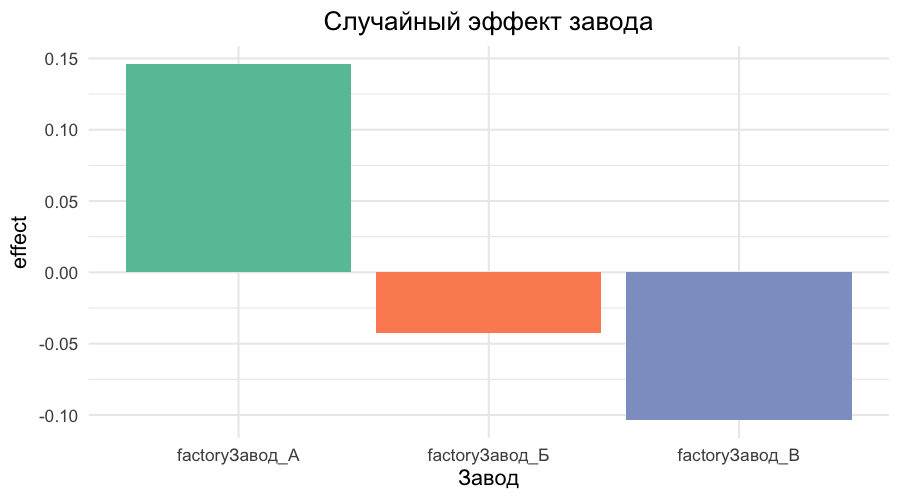

In [7]:
ggplot(factory_eff, aes(x = factory, y = effect, fill = factory)) +
  geom_col() +
  scale_fill_brewer(palette = "Set2", guide = "none") +
  labs(title = "Случайный эффект завода", x = "Завод", y = "effect") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


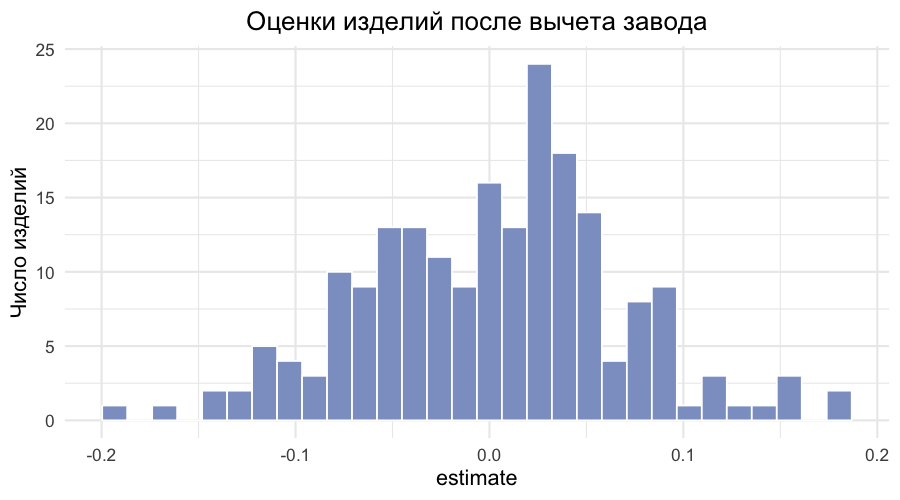

In [8]:
ggplot(data.frame(estimate = as.numeric(est_item)), aes(x = estimate)) +
  geom_histogram(bins = 30, fill = "#8DA0CB", color = "white") +
  labs(title = "Оценки изделий после вычета завода", x = "estimate", y = "Число изделий") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# Заключение

Если завод не вынести в случайный эффект, его уровень «прилипнет» к оценкам изделий с этой площадки. Блочная K разделяет сходство по линии и независимый вклад завода.
